# Praktikum Analisis Sentimen Mitigasi Bencana — Neural Network (MLP)

**Metode:** data X/Twitter atau komentar YouTube asli → cleansing → label sederhana berbasis leksikon → diagram distribusi → WordCloud → TF-IDF → Neural Network (MLP) → evaluasi → prediksi teks baru.

**Ketentuan dataset:** minimum **300 unggahan/komentar asli**; CSV bernama `tweet_data.csv` dengan kolom `created_at`, `username`, `full_text`. Nama file mengikuti tugas; **jika sumbernya YouTube, laporkan sebagai komentar YouTube, bukan tweet**.

Notebook ini dibuat **mandiri (standalone)** untuk VS Code/Jupyter dan Google Colab. Tidak ada data penelitian atau nilai metrik yang direkayasa. Untuk pengambilan data, gunakan `crawl_x.py` atau `crawl_youtube.py` dalam ZIP proyek dan simpan hasilnya sebagai `tweet_data.csv`.

## Langkah 0 — Persiapan pustaka

Di **VS Code**, aktifkan virtual environment proyek lalu instal: `python -m pip install -r requirements.txt`. Di **Colab**, jalankan sel instalasi di bawah bila paket belum tersedia.

In [1]:
# Jalankan baris berikut hanya jika library belum terinstal:
# %pip install pandas numpy scikit-learn matplotlib wordcloud joblib

import re
import html
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import joblib
from IPython.display import display

OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok=True)
CLASSES = ['negatif', 'netral', 'positif']
COLORS = {'negatif': '#D45E68', 'netral': '#D0A03A', 'positif': '#219C78'}
EMOJI = {'negatif': '😟', 'netral': '😐', 'positif': '😊'}
print('Pustaka siap; hasil grafik dan CSV akan disimpan ke:', OUTPUT_DIR.resolve())

Pustaka siap; hasil grafik dan CSV akan disimpan ke: /Users/mochammadmarillivio/Downloads/Praktikum_Sentimen_Mitigasi_Bencana/output


## Langkah 1 — Ambil data dan buka CSV

Ambil **≥300 data nyata** dengan skrip `crawl_x.py` / `crawl_youtube.py` pada folder proyek. Pada VS Code, notebook otomatis membaca `tweet_data.csv` di folder kerja. Pada Google Colab, sel berikut akan menawarkan unggah file bila CSV belum ditemukan. Pastikan data benar-benar berasal dari platform yang disebutkan dan memiliki izin penggunaan yang sesuai.

In [2]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("tweet_data.csv")

print("Folder notebook:", Path.cwd())
print("Lokasi dataset:", DATA_PATH.resolve())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Periksa lokasi tweet_data.csv."
    )

raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

required = {"created_at", "username", "full_text"}
missing = required - set(raw.columns)

if missing:
    raise ValueError(f"Kolom tidak tersedia: {missing}")

print("Jumlah data mentah:", len(raw))

if raw.empty:
    raise ValueError(
        "Dataset masih kosong. Jalankan crawler terlebih dahulu."
    )

if len(raw) < 300:
    print("PERINGATAN: Dataset belum mencapai 300 data.")
else:
    print("Dataset memenuhi jumlah minimal 300 data.")

display(raw.head(10))

Folder notebook: /Users/mochammadmarillivio/Downloads/Praktikum_Sentimen_Mitigasi_Bencana
Lokasi dataset: /Users/mochammadmarillivio/Downloads/Praktikum_Sentimen_Mitigasi_Bencana/tweet_data.csv
Jumlah data mentah: 350
Dataset memenuhi jumlah minimal 300 data.


,created_at,username,full_text,source,source_url
0,2026-11-01T05:34:18Z,@yovitapartners,jurnalis tuhhh jangan samperin gunung lagi dlm...,YouTube,https://www.youtube.com/watch?v=am9inBskvFA&lc...
1,2021-04-07T10:04:55Z,@charles0854,"Biasalah gara"" tugas geografi jdi bersilaturah...",YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
2,2022-11-22T08:48:02Z,@yayaaa1912,"Stay Safe semuanya terutama warga Cianjur, sem...",YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
3,2019-08-02T13:50:59Z,@rautan_3308,"Sy dr lombok, dan sy tau rasanya dguncang bgtu...",YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
4,2021-04-07T00:17:48Z,@BengkelPantura,Pasti ke sini gara² tugas 🗿,YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
5,2021-04-15T05:23:22Z,@jfar.,Gak ingatlah gua aja belum lahir gimana mau in...,YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
6,2026-02-10T02:28:12Z,@aztharchanel1965,Trimksh ilmunya,YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
7,2024-04-03T04:43:10Z,@MuhammadRidho-b6u,Tanggap tangkas tangguh menghadapi bencana 3T 🙏,YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
8,2019-08-09T05:38:19Z,@ekasetiawaty5269,Mudahan di kalimantan selstan tidak terjadi am...,YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...
9,2019-08-02T12:21:18Z,@dimaspradiptamm,Di Banten gempa :(,YouTube,https://www.youtube.com/watch?v=nk38uvgEWkM&lc...


## Langkah 2–4 — Cleansing dan pelabelan Rule-Based

URL, mention, hashtag (termasuk kata tagarnya), angka, tanda baca dan spasi berlebih dihapus; teks diubah ke huruf kecil. Label otomatis ditentukan dengan menghitung kata positif dan negatif. Kata yang sama banyak menghasilkan label **netral**. **Keterbatasan:** keberadaan kata seperti *banjir* belum tentu menunjukkan opini negatif; tinjau beberapa sampel label secara manual.

In [3]:
POSITIVE_WORDS = {
    'aman', 'selamat', 'siaga', 'siap', 'sigap', 'tanggap', 'cepat', 'baik', 'bagus',
    'efektif', 'berhasil', 'terbantu', 'membantu', 'bantuan', 'peduli', 'terlindungi',
    'perlindungan', 'edukasi', 'antisipasi', 'pulih', 'pemulihan', 'lancar', 'mantap',
    'apresiasi', 'hebat', 'terlatih', 'tertib', 'waspada', 'tenang', 'solid', 'sukses'
}
NEGATIVE_WORDS = {
    'banjir', 'gempa', 'longsor', 'kebakaran', 'bahaya', 'berbahaya', 'parah',
    'rusak', 'kerusakan', 'terlambat', 'lambat', 'gagal', 'panik', 'takut', 'khawatir',
    'korban', 'meninggal', 'terjebak', 'kacau', 'macet', 'buruk', 'kurang', 'lemah',
    'minim', 'krisis', 'hancur', 'celaka', 'terancam', 'mengungsi', 'bencana', 'darurat'
}
STOPWORDS_ID = {
    'yang', 'dan', 'di', 'ke', 'dari', 'untuk', 'dengan', 'atau', 'pada', 'ini', 'itu',
    'ada', 'adalah', 'akan', 'juga', 'sudah', 'agar', 'karena', 'oleh', 'jadi',
    'sebagai', 'dalam', 'lebih', 'saat', 'para', 'mereka', 'kami', 'kita', 'saya',
    'aku', 'anda', 'tidak', 'bukan', 'masih', 'bisa', 'harus', 'telah', 'tahun',
    'hari', 'sekarang', 'sangat', 'terus', 'sebuah', 'bagi', 'tentang', 'nya',
    'yg', 'ya', 'nih', 'sih', 'dong', 'aja', 'tp', 'tapi', 'pun', 'lah'
}

def clean_text(value):
    text = html.unescape(str(value))
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'#[\w]+', ' ', text)
    text = text.lower()
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def label_sentiment(cleaned):
    tokens = cleaned.split()
    n_positive = sum(t in POSITIVE_WORDS for t in tokens)
    n_negative = sum(t in NEGATIVE_WORDS for t in tokens)
    if n_positive > n_negative:
        return 'positif'
    if n_negative > n_positive:
        return 'negatif'
    return 'netral'

data = raw.copy()
for col in ['created_at', 'username', 'full_text']:
    data[col] = data[col].fillna('').astype(str)
data = data.loc[data['full_text'].str.strip().ne('')].copy()
data['clean_text'] = data['full_text'].map(clean_text)
data = data.loc[data['clean_text'].str.len() >= 8].copy()
data = data.drop_duplicates(subset='clean_text').reset_index(drop=True)
data['sentimen'] = data['clean_text'].map(label_sentiment)
print('Jumlah data setelah cleansing dan deduplikasi:', len(data))
if len(data) < 300:
    print('PERINGATAN: data bersih kurang dari 300. Tambahkan data sumber asli.')
display(data[['created_at', 'username', 'full_text', 'clean_text', 'sentimen']].head(10))
data.to_csv(OUTPUT_DIR / 'tweet_data_berlabel.csv', index=False, encoding='utf-8-sig')

Jumlah data setelah cleansing dan deduplikasi: 336


,created_at,username,full_text,clean_text,sentimen
0,2026-11-01T05:34:18Z,@yovitapartners,jurnalis tuhhh jangan samperin gunung lagi dlm...,jurnalis tuhhh jangan samperin gunung lagi dlm...,positif
1,2021-04-07T10:04:55Z,@charles0854,"Biasalah gara"" tugas geografi jdi bersilaturah...",biasalah gara tugas geografi jdi bersilaturahm...,netral
2,2022-11-22T08:48:02Z,@yayaaa1912,"Stay Safe semuanya terutama warga Cianjur, sem...",stay safe semuanya terutama warga cianjur semo...,netral
3,2019-08-02T13:50:59Z,@rautan_3308,"Sy dr lombok, dan sy tau rasanya dguncang bgtu...",sy dr lombok dan sy tau rasanya dguncang bgtu ...,netral
4,2021-04-07T00:17:48Z,@BengkelPantura,Pasti ke sini gara² tugas 🗿,pasti ke sini gara tugas,netral
5,2021-04-15T05:23:22Z,@jfar.,Gak ingatlah gua aja belum lahir gimana mau in...,gak ingatlah gua aja belum lahir gimana mau ingat,netral
6,2026-02-10T02:28:12Z,@aztharchanel1965,Trimksh ilmunya,trimksh ilmunya,netral
7,2024-04-03T04:43:10Z,@MuhammadRidho-b6u,Tanggap tangkas tangguh menghadapi bencana 3T 🙏,tanggap tangkas tangguh menghadapi bencana t,netral
8,2019-08-09T05:38:19Z,@ekasetiawaty5269,Mudahan di kalimantan selstan tidak terjadi am...,mudahan di kalimantan selstan tidak terjadi am...,netral
9,2019-08-02T12:21:18Z,@dimaspradiptamm,Di Banten gempa :(,di banten gempa,negatif


## Langkah 5 — Distribusi sentimen (bar chart dan pie chart)

Amati kategori terbanyak dan apakah distribusinya seimbang. Jangan simpulkan sikap semua masyarakat Indonesia dari sampel yang mungkin tidak representatif.

Distribusi sentimen:


,sentimen,jumlah,persentase
0,negatif,52,15.48
1,netral,228,67.86
2,positif,56,16.67


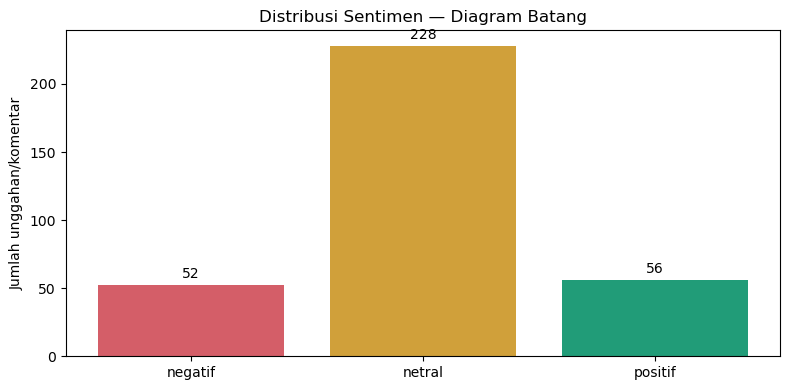

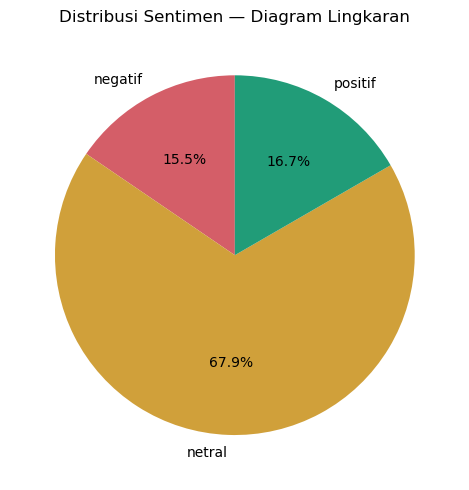

In [4]:
counts = data['sentimen'].value_counts().reindex(CLASSES, fill_value=0)
print('Distribusi sentimen:')
display(pd.DataFrame({'sentimen': counts.index, 'jumlah': counts.values,
                      'persentase': (counts / max(len(data), 1) * 100).round(2).values}))
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(CLASSES, counts.values, color=[COLORS[s] for s in CLASSES])
ax.bar_label(bars, padding=3)
ax.set(ylabel='Jumlah unggahan/komentar', title='Distribusi Sentimen — Diagram Batang')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_distribusi_batang.png', dpi=160)
plt.show()
plt.close(fig)

nonzero = counts[counts > 0]
fig, ax = plt.subplots(figsize=(6, 5))
if len(nonzero):
    ax.pie(nonzero.values, labels=nonzero.index, autopct='%1.1f%%', startangle=90,
           colors=[COLORS[s] for s in nonzero.index])
ax.set_title('Distribusi Sentimen — Diagram Lingkaran')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '02_distribusi_pie.png', dpi=160)
plt.show()
plt.close(fig)

## Langkah 6 — WordCloud dan frekuensi kata setiap sentimen

Ukuran kata mencerminkan frekuensi dalam kategori; bukan besarnya pengaruh kata tersebut pada prediksi model. Warna dibedakan sesuai sentimen.


POSITIF — 56 data


,kata,frekuensi
0,membantu,14
1,semoga,12
2,siap,9
3,bagus,8
4,sungai,8
5,pak,8
6,cepat,7
7,semua,7
8,selalu,7
9,terima,6


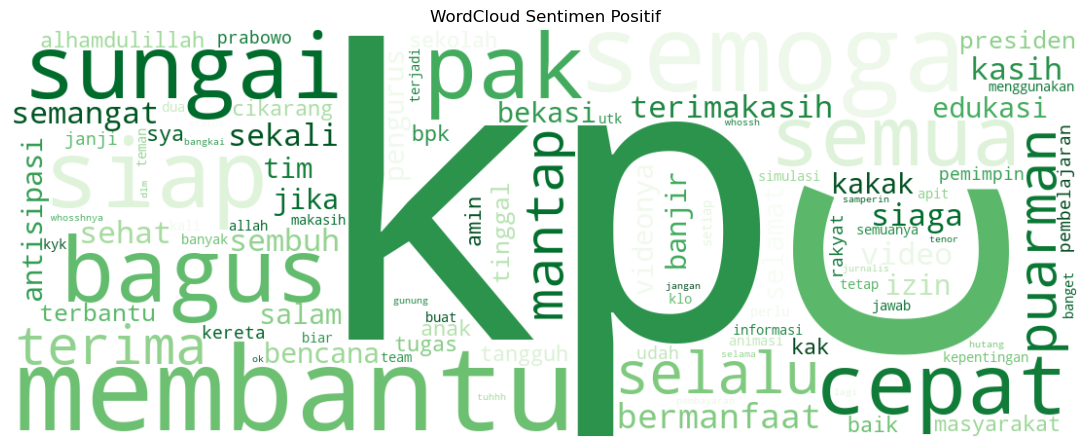


NETRAL — 228 data


,kata,frekuensi
0,izin,54
1,video,40
2,kak,39
3,tugas,32
4,pak,26
5,buat,22
6,terimakasih,21
7,videonya,18
8,semoga,17
9,terima,16


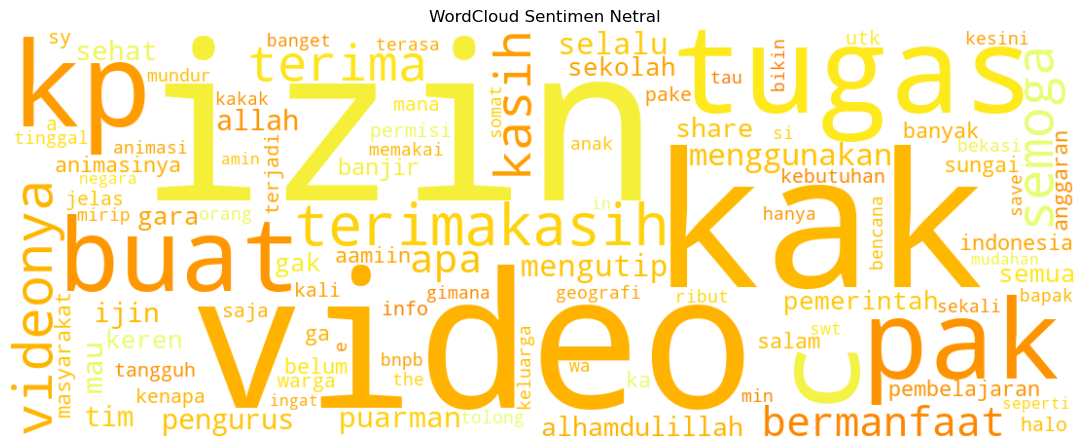


NEGATIF — 52 data


,kata,frekuensi
0,gempa,35
1,bencana,22
2,bumi,16
3,banjir,11
4,terjadi,9
5,anggaran,8
6,klo,7
7,sungai,7
8,sekolah,7
9,mohon,6


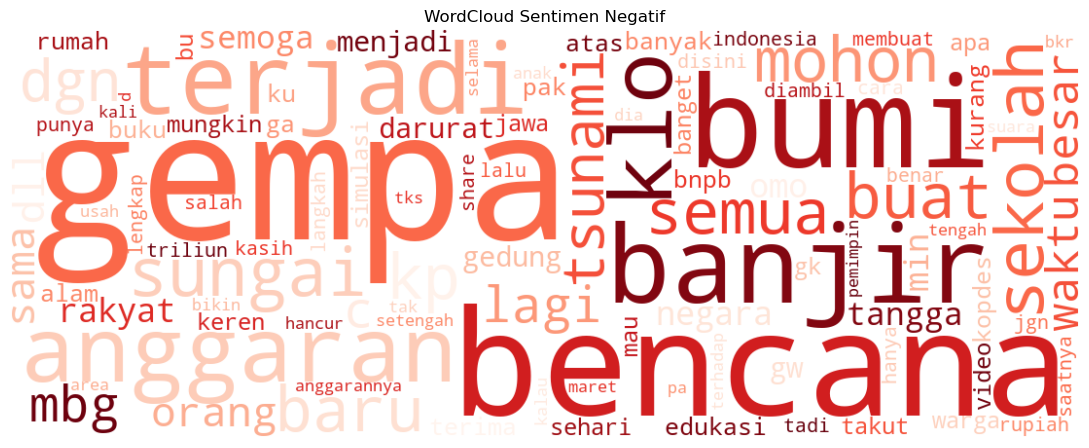

In [5]:
CMAPS = {'negatif': 'Reds', 'netral': 'Wistia', 'positif': 'Greens'}
for sentiment in ['positif', 'netral', 'negatif']:
    texts = data.loc[data['sentimen'].eq(sentiment), 'clean_text'].tolist()
    print(f'\n{sentiment.upper()} — {len(texts)} data')
    if not texts:
        print('Kelas kosong: WordCloud tidak dapat dibuat.'); continue
    frequency = Counter(word for text in texts for word in text.split()
                        if len(word) >= 3 and word not in STOPWORDS_ID)
    display(pd.DataFrame(frequency.most_common(10), columns=['kata', 'frekuensi']))
    if not frequency:
        print('Tidak ada kata setelah stopwords dihilangkan.'); continue
    cloud = WordCloud(width=1100, height=420, background_color='white',
                      stopwords=STOPWORDS_ID, colormap=CMAPS[sentiment],
                      collocations=False, max_words=100).generate(' '.join(texts))
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(f'WordCloud Sentimen {sentiment.title()}')
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'03_wordcloud_{sentiment}.png', dpi=160)
    plt.show()
    plt.close(fig)

## Langkah 7 — Latih Neural Network (TF-IDF + MLP)

Pembagian **80% data latih dan 20% data uji** dengan stratifikasi kelas, `random_state=42`. Pipeline mengadaptasi TF-IDF **hanya pada data latih**, sehingga menghindari kebocoran informasi dari data uji. Arsitektur: 1 hidden layer × 100 neuron, ReLU, Adam, maksimal 250 iterasi.

In [6]:
if len(data) < 30:
    raise ValueError('Data bersih kurang dari 30. Tambah data asli agar evaluasi cukup layak.')
class_counts = data['sentimen'].value_counts()
if len(class_counts) < 2:
    raise ValueError('Data hanya berisi satu sentimen. Perlu sekurang-kurangnya dua kelas.')
if class_counts.min() < 2:
    raise ValueError('Setiap kelas yang hadir minimal dua data untuk stratified split.')

X_train, X_test, y_train, y_test = train_test_split(
    data['clean_text'], data['sentimen'], test_size=0.20,
    random_state=42, stratify=data['sentimen']
)
model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)),
    ('mlp', MLPClassifier(hidden_layer_sizes=(100,), activation='relu',
                          solver='adam', max_iter=250, random_state=42))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f'Jumlah training: {len(X_train)} | testing: {len(X_test)}')
print('Kelas model:', list(model.named_steps['mlp'].classes_))

Jumlah training: 268 | testing: 68
Kelas model: ['negatif', 'netral', 'positif']


## Langkah 8 — Evaluasi akurasi, presisi, recall, F1 dan Confusion Matrix

Presisi, recall, dan F1 dihitung menggunakan **weighted average** sesuai jumlah sampel setiap kelas. Confusion matrix: baris = label aktual dari rule-based, kolom = prediksi MLP.

Metrik evaluasi:


,Akurasi,Presisi (weighted),Recall (weighted),F1-score (weighted)
0,0.7059,0.6975,0.7059,0.6766


Classification report:


,precision,recall,f1-score,support
negatif,0.750000,0.272727,0.400000,11.000000
netral,0.732143,0.891304,0.803922,46.000000
positif,0.500000,0.363636,0.421053,11.000000
accuracy,0.705882,0.705882,0.705882,0.705882
macro avg,0.660714,0.509223,0.541658,68.000000
weighted avg,0.697479,0.705882,0.676647,68.000000


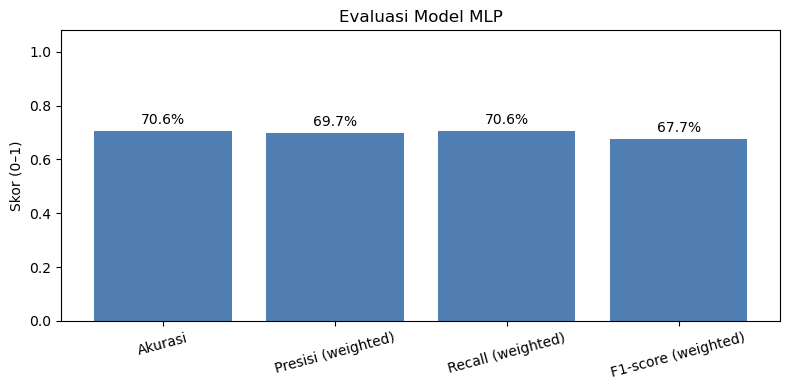

In [7]:
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average='weighted', zero_division=0
)
metrics = {
    'Akurasi': accuracy_score(y_test, y_pred),
    'Presisi (weighted)': precision,
    'Recall (weighted)': recall,
    'F1-score (weighted)': f1,
}
metrics_df = pd.DataFrame([metrics])
print('Metrik evaluasi:')
display(metrics_df.style.format('{:.4f}'))
labels_present = [c for c in CLASSES if c in class_counts.index]
report = pd.DataFrame(classification_report(
    y_test, y_pred, labels=labels_present, output_dict=True, zero_division=0
)).T
print('Classification report:')
display(report)
metrics_df.to_csv(OUTPUT_DIR / 'hasil_evaluasi_nn.csv', index=False)
report.to_csv(OUTPUT_DIR / 'classification_report.csv')
results_test = pd.DataFrame({'clean_text': X_test.to_numpy(),
                             'label_rule_based': y_test.to_numpy(),
                             'prediksi_mlp': y_pred})
results_test.to_csv(OUTPUT_DIR / 'prediksi_data_uji.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(8, 4))
rect = ax.bar(list(metrics.keys()), list(metrics.values()), color='#527FB3')
ax.bar_label(rect, labels=[f'{v:.1%}' for v in metrics.values()], padding=3)
ax.set_ylim(0, 1.08)
ax.tick_params(axis='x', rotation=15)
ax.set(ylabel='Skor (0–1)', title='Evaluasi Model MLP')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '04_metrik_evaluasi.png', dpi=160)
plt.show()
plt.close(fig)

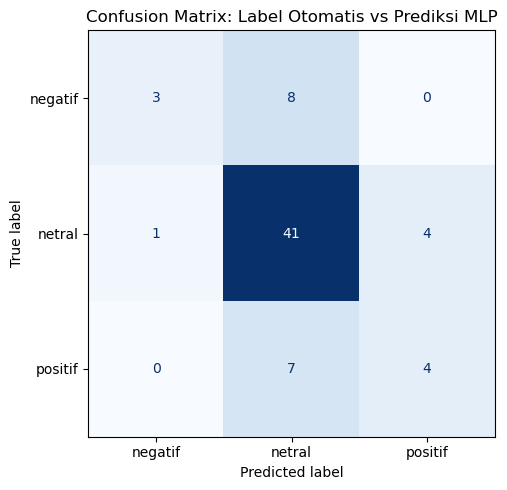

Contoh hasil prediksi data testing:


,clean_text,label_rule_based,prediksi_mlp
0,kak izin ada yg aku rekam layar ya buat tugas ...,netral,netral
1,terimakasih tim kp c,netral,netral
2,terima kasih pak sangat bermanfaat dan membant...,positif,netral
3,kerenn pollll makasii mainn jadi pahammm,netral,netral
4,hhh ada yang bawa anak,netral,positif
5,permisi bang sy mau nanya itu ngeditnya pake a...,netral,netral
6,bagus simulasi nya bagus,positif,positif
7,pasti ke sini gara tugas,netral,netral
8,mirip keluarga somat,netral,netral
9,sangat bermanfaat buat masyarakat,netral,netral


In [8]:
cm = confusion_matrix(y_test, y_pred, labels=labels_present)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_present)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title('Confusion Matrix: Label Otomatis vs Prediksi MLP')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '05_confusion_matrix.png', dpi=160)
plt.show()
plt.close(fig)
print('Contoh hasil prediksi data testing:')
display(results_test.head(10))

## Langkah 9 — Prediksi teks baru dan probabilitas

Ubah `new_text` menjadi komentar Anda sendiri. Model memproses teks dengan fungsi cleansing yang sama. Nilai `predict_proba` merupakan skor probabilitas model yang **belum tentu terkalibrasi**.

Teks asli: Sistem peringatan dini dan pelatihan evakuasi sangat membantu warga agar tetap aman.
Teks bersih: sistem peringatan dini dan pelatihan evakuasi sangat membantu warga agar tetap aman
Hasil prediksi: 😊 POSITIF


,sentimen,probabilitas
0,negatif,0.114482
1,netral,0.428974
2,positif,0.456545


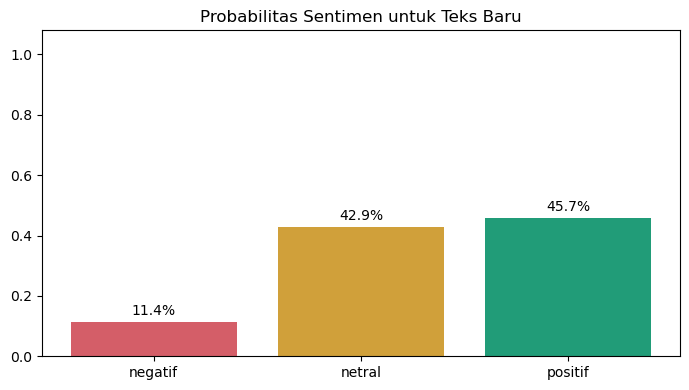

In [9]:
def predict_new_text(text):
    cleaned = clean_text(text)
    if not cleaned:
        raise ValueError('Masukkan kalimat yang mengandung kata, bukan sekadar URL/simbol.')
    label = str(model.predict([cleaned])[0])
    proba = model.predict_proba([cleaned])[0]
    names = model.named_steps['mlp'].classes_
    probs = {name: float(value) for name, value in zip(names, proba)}
    return label, probs, cleaned

new_text = 'Sistem peringatan dini dan pelatihan evakuasi sangat membantu warga agar tetap aman.'
predicted, probabilities, cleaned = predict_new_text(new_text)
print('Teks asli:', new_text)
print('Teks bersih:', cleaned)
print('Hasil prediksi:', EMOJI[predicted], predicted.upper())
prob_df = pd.DataFrame({'sentimen': list(probabilities),
                        'probabilitas': list(probabilities.values())})
display(prob_df)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(prob_df['sentimen'], prob_df['probabilitas'],
              color=[COLORS[x] for x in prob_df['sentimen']])
ax.bar_label(bars, labels=[f'{p:.1%}' for p in prob_df['probabilitas']], padding=3)
ax.set_ylim(0, 1.08)
ax.set_title('Probabilitas Sentimen untuk Teks Baru')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '06_prediksi_teks_baru.png', dpi=160)
plt.show()
plt.close(fig)

## Langkah 10 — Simpan model, kumpulkan screenshot, dan susun laporan

- `output/tweet_data_berlabel.csv` memuat teks bersih dan label otomatis.
- `output/hasil_evaluasi_nn.csv`, `classification_report.csv`, `prediksi_data_uji.csv` memuat hasil nyata pelatihan.
- Gambar 01–06 (`.png`) dapat digunakan untuk dokumentasi laporan, **tambahkan screenshot dashboard Streamlit** dari `app_sentimen_nn.py` sesuai ketentuan dosen.
- Untuk laporan: jelaskan jumlah sebelum/sesudah cleansing, distribusi dan WordCloud, metrik, kekeliruan confusion matrix, hasil prediksi, serta **keterbatasan label otomatis**. Jangan membuat klaim performa terhadap sentimen manusia tanpa sampel yang dianotasi manusia.

In [10]:
model_path = OUTPUT_DIR / 'model_mlp_tfidf.joblib'
joblib.dump(model, model_path)
print('Model tersimpan di:', model_path)
print('File output:')
for file in sorted(OUTPUT_DIR.glob('*')):
    if file.is_file():
        print(' -', file)
print('\nLangkah berikutnya: jalankan `streamlit run app_sentimen_nn.py` dari terminal proyek, kemudian ambil screenshot dashboard.')

Model tersimpan di: output/model_mlp_tfidf.joblib
File output:
 - output/01_distribusi_batang.png
 - output/02_distribusi_pie.png
 - output/03_wordcloud_negatif.png
 - output/03_wordcloud_netral.png
 - output/03_wordcloud_positif.png
 - output/04_metrik_evaluasi.png
 - output/05_confusion_matrix.png
 - output/06_prediksi_teks_baru.png
 - output/classification_report.csv
 - output/hasil_evaluasi_nn.csv
 - output/model_mlp_tfidf.joblib
 - output/prediksi_data_uji.csv
 - output/tweet_data_berlabel.csv

Langkah berikutnya: jalankan `streamlit run app_sentimen_nn.py` dari terminal proyek, kemudian ambil screenshot dashboard.
